# <font color = Blue> **Trabalho Final — Problema 05 - Gasolina EUA**

**`Objetivo do trabalho`**:  modelar um *problema real* e fazer predição utilizando os modelos de séries temporais estudados na disciplina.

**`Problema Real`**: Modelagem e predição de volume semanal de gasolina disponibilizado ao mercado dos Estados Unidos, expresso como média diária - **de 08/02/1991 a 20/01/2017**.

**`Tarefa`**: encontrar o melhor modelo e fazer a predição (**forecast**) de volume semanal de gasolina disponibilizado ao mercado dos Estados Unidos, expresso como média diária para um horizonte **`h`**, que será definido adiante.


## <font color = Blue> **Configuração Inicial e Carregamento da Série**
Vamos instalar/importar as bibliotecas necessárias e carregar a série temporal.

- **Bibliotecas básicas**

In [35]:
#Bibliotecas básicas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import root_mean_squared_error
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from sklearn.tree import DecisionTreeRegressor

- **Carregamento da Série `Gasolina EUA`**

Fonte e preparação: U.S. Energy Information Administration (EIA), série WGFUPUS2. Observações semanais, em milhões de barris/dia; indicador de oferta ao mercado, usado como aproximação da demanda. Calendário semanal alinhado às datas da EIA; o registro de 10/10/1997, ausente no XLS atual da EIA, foi preservado da série publicada fpp2::gasoline (8,221). Os demais valores coincidem integralmente. Fonte complementar: https://pkg.robjhyndman.com/fpp2/reference/gasoline.html . Fonte: https://www.eia.gov/dnav/pet/hist/LeafHandler.ashx?n=PET&s=WGFUPUS2&f=W

O CSV será carregado diretamente do repositório GitHub `MiroPlacido/Datasets`: `AST_2026_Problema_05_Gasolina_EUA.csv`.


In [3]:
url = 'https://raw.githubusercontent.com/MiroPlacido/Datasets/refs/heads/main/AST_2026_Problema_05_Gasolina_EUA.csv'
df = pd.read_csv(url)

# Visualização do df
df.head()


,Data,Volume_Milhoes_Barris_Dia
0,1991-02-08,6.621
1,1991-02-15,6.433
2,1991-02-22,6.582
3,1991-03-01,7.224
4,1991-03-08,6.875


In [4]:
# Identificando a data e setando como índice
df["Data"] = pd.to_datetime(df["Data"])
df = df.set_index("Data")

# Configurar frequência para SEMANAL (para evitar warnings de inferência)
df.index.freq = 'W-FRI'

# Visualizando
df.head()


,Volume_Milhoes_Barris_Dia
Data,
1991-02-08,6.621
1991-02-15,6.433
1991-02-22,6.582
1991-03-01,7.224
1991-03-08,6.875


- **Plot da série ORIGINAL**

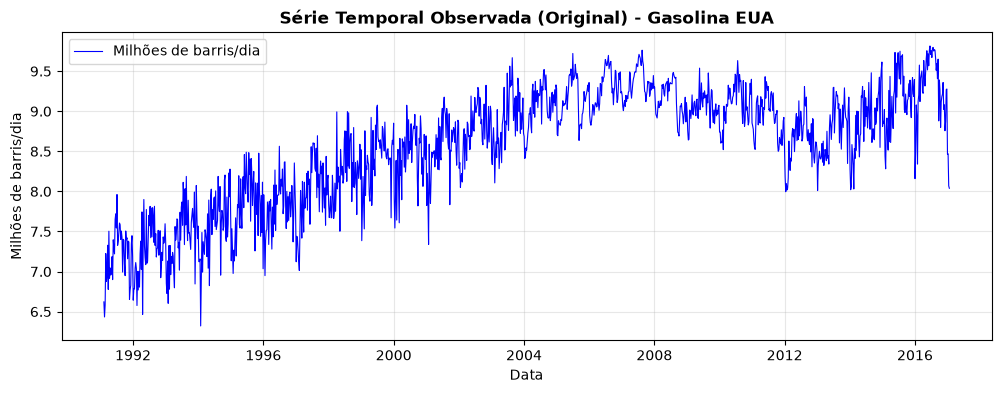

In [5]:
# Visualização da série
plt.figure(figsize=(12, 4))
plt.plot(df, label='Milhões de barris/dia', color='blue', linewidth=0.8)
plt.title('Série Temporal Observada (Original) - Gasolina EUA', fontweight = "bold")
plt.xlabel('Data')
plt.ylabel('Milhões de barris/dia')
plt.grid(True, alpha = 0.3)
plt.legend()
plt.show()


## <font color = Blue> **Parte 1 - Divisão ($split$) da série temporal**


- **Defina e justifique o horizonte `h` de predição**.
- Um horizonte múltiplo do período sazonal `m` é conveniente;
- Reserve os **últimos `h` semanas para teste**, utilizando os dados anteriores como treino e validação;


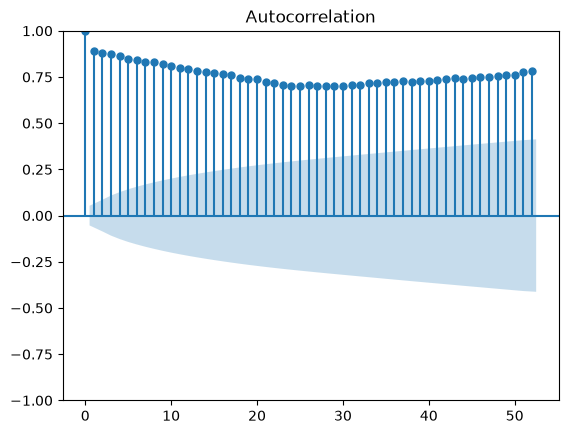

In [6]:
plot_acf(df.Volume_Milhoes_Barris_Dia, lags=52)
plt.show()

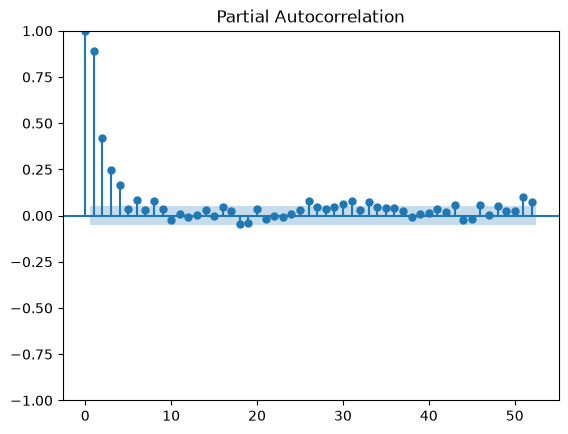

In [7]:
plot_pacf(df.Volume_Milhoes_Barris_Dia, lags=52)
plt.show()

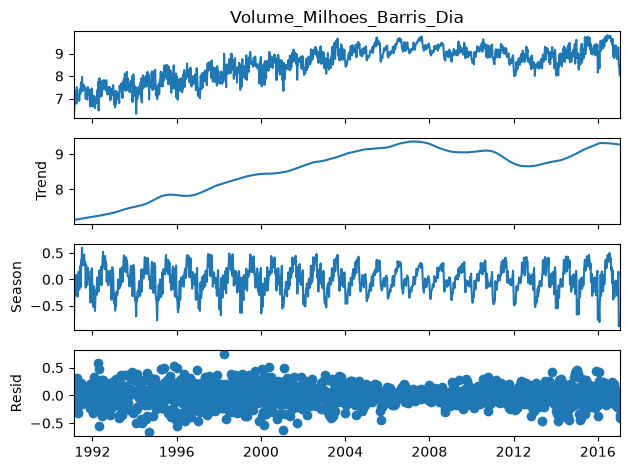

In [8]:
stl = STL(df.Volume_Milhoes_Barris_Dia)
res = stl.fit()
res.plot()
plt.show()

Identificamos que a sazonalidade é de um ano. (52 semanas)

In [9]:
m = 52   # Período sazonal (semanas em um ano)
h = 52   # Horizonte de predição: 1 ciclo sazonal completo

train_df = df.iloc[:-h]
test_df = df.iloc[-h:]

print(f"Total: {len(df)} semanas")
print(f"Treino: {len(train_df)} semanas ({train_df.index.min().date()} a {train_df.index.max().date()})")
print(f"Teste: {len(test_df)} semanas ({test_df.index.min().date()} a {test_df.index.max().date()})")

Total: 1355 semanas
Treino: 1303 semanas (1991-02-08 a 2016-01-22)
Teste: 52 semanas (2016-01-29 a 2017-01-20)


- **Plot o split da série, isto é, os conjuntos de treino e teste**

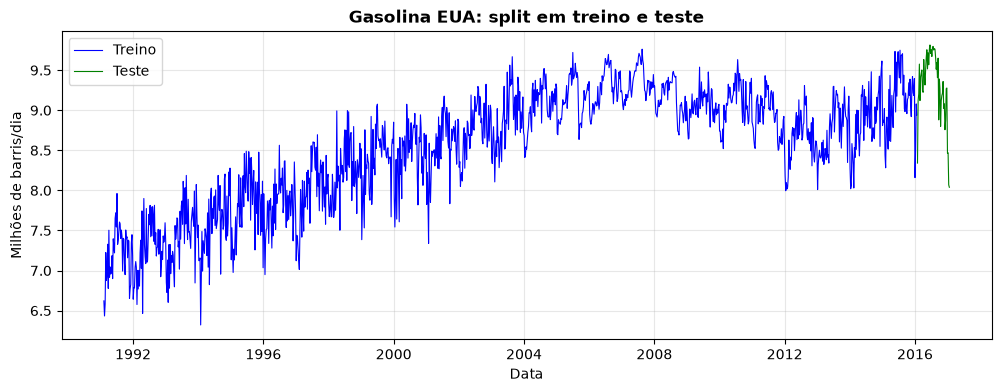

In [10]:
plt.figure(figsize=(12, 4))
plt.xlim()
plt.plot(train_df.Volume_Milhoes_Barris_Dia, label="Treino", color="blue", linewidth=0.8)
plt.plot(test_df.Volume_Milhoes_Barris_Dia, label="Teste", color="green", linewidth=0.8)
plt.title("Gasolina EUA: split em treino e teste", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Milhões de barris/dia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## <font color = Blue> **Parte 2 - Tratamento da Série (Detecção e tratamento de anomalias)**


Verifique se o conjunto de treino precisa de algum tratamento. Deixe clara sua escolha, explicando o motivo.
- **Obs:** a escolha pode ser "nada a ajustar".



In [11]:
train_df.head()

,Volume_Milhoes_Barris_Dia
Data,
1991-02-08,6.621
1991-02-15,6.433
1991-02-22,6.582
1991-03-01,7.224
1991-03-08,6.875


In [12]:
train_df.isnull().sum()

Volume_Milhoes_Barris_Dia    0
dtype: int64

In [13]:
train_df.duplicated().sum()

np.int64(305)

In [14]:
df.describe(include='all')

,Volume_Milhoes_Barris_Dia
count,1355.000000
mean,8.553304
std,0.731086
min,6.321000
25%,8.049000
50%,8.713000
75%,9.121500
max,9.815000


In [15]:
serie_treino = train_df.Volume_Milhoes_Barris_Dia

print("Valores nulos:", serie_treino.isna().sum())
print("Datas duplicadas:", serie_treino.index.duplicated().sum())

# Verifica se todas as datas estão espaçadas de exatamente 7 dias
intervalos = serie_treino.index.to_series().diff().dropna()
print("Intervalos entre datas:", intervalos.value_counts().to_dict())

serie_treino.describe()

Valores nulos: 0
Datas duplicadas: 0
Intervalos entre datas: {Timedelta('7 days 00:00:00'): 1302}


count    1303.000000
mean        8.523015
std         0.724014
min         6.321000
25%         8.016500
50%         8.684000
75%         9.090000
max         9.762000
Name: Volume_Milhoes_Barris_Dia, dtype: float64

Nada a ajustar.

## <font color = Blue> **Parte 3 - Análise e Diagnóstico**
- Faça plot de um período curto do conjunto de treino (trecho ampliado) para identificar visualmente sazonalidade;
- Faça análises de autocorrelação, estacionariedade e sazonalidade utilizando o conjunto de treino.


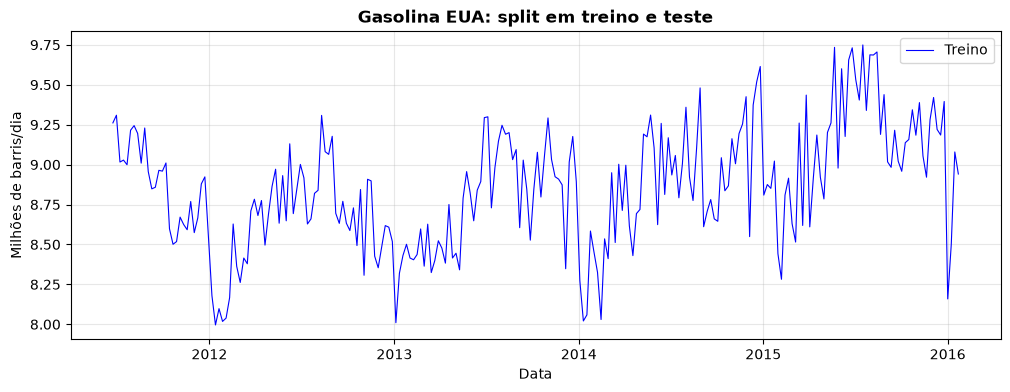

In [16]:
plt.figure(figsize=(12, 4))
plt.xlim()
plt.plot(train_df[-240:].Volume_Milhoes_Barris_Dia, label="Treino", color="blue", linewidth=0.8)
plt.title("Gasolina EUA: split em treino e teste", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Milhões de barris/dia")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

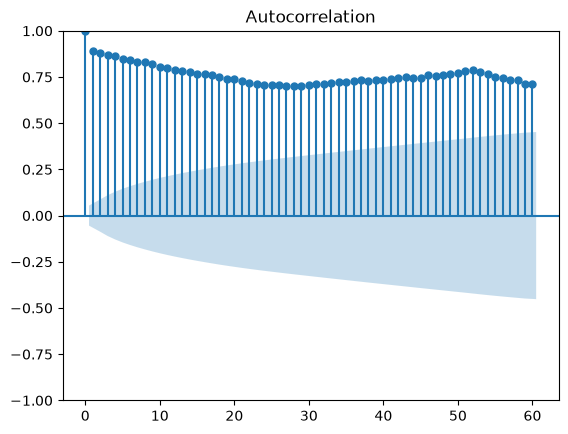

In [17]:
plot_acf(train_df.Volume_Milhoes_Barris_Dia, lags=60)
plt.show()

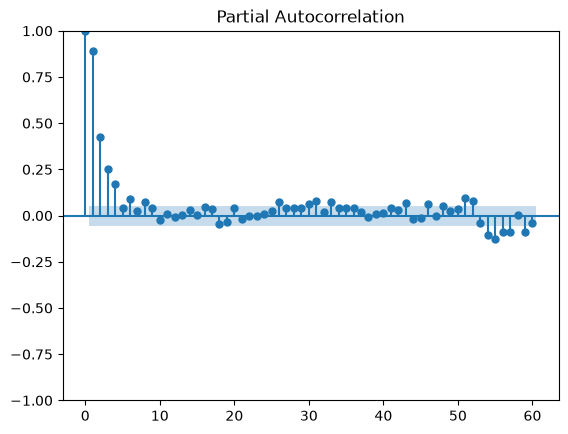

In [18]:
plot_pacf(train_df.Volume_Milhoes_Barris_Dia, lags=60)
plt.show()

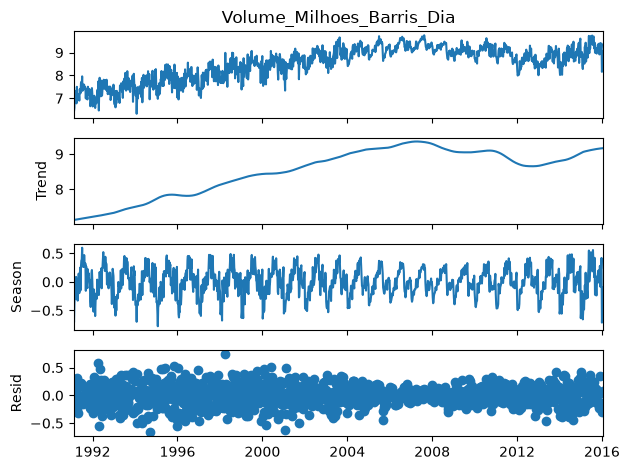

In [19]:
stl = STL(train_df.Volume_Milhoes_Barris_Dia)
res = stl.fit()
res.plot()
plt.show()

In [20]:
adfuller(train_df.Volume_Milhoes_Barris_Dia.values, result_object=True)

ADFullerResult
ADF Statistic: -2.76068
P-value: 0.06411
Used Lag: 8
Nobs: 1294
Critical Values: {'1%': np.float64(-3.4354136163971782), '5%': np.float64(-2.8637761637845895), '10%': np.float64(-2.5679605492954045)}

## <font color = Blue> **Parte 4 - Treinamento e seleção do modelo**

- Compare **ETSModel, ARIMA, SARIMA, árvore de decisão, Prophet e LSTM**, *justificando eventual não aplicação*;
- Para seleção do modelo e seus hiperparâmetros, utilize **Cross Validation Temporal exclusivamente dentro do conjunto de treino**, com as mesmas janelas para todos os candidatos e blocos de validação de comprimento **`h`**;
- Selecione pelo **RMSE médio das janelas de validação**, calculado na escala original (milhões de barris por dia);
- Todos os modelos devem prever os **`h` períodos a partir da mesma origem**, sem utilizar valores reais do bloco previsto. Para árvore de decisão e LSTM, explicite a estratégia de previsão (recursiva, direta ou de múltiplas saídas).


In [21]:
dif1 = train_df.Volume_Milhoes_Barris_Dia.diff(1).dropna()
dif1.head()

Data
1991-02-15   -0.188
1991-02-22    0.149
1991-03-01    0.642
1991-03-08   -0.349
1991-03-15    0.072
Freq: W-FRI, Name: Volume_Milhoes_Barris_Dia, dtype: float64

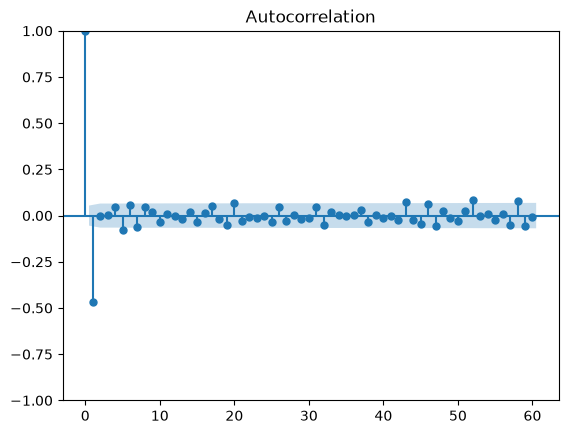

In [22]:
plot_acf(dif1, lags=60)
plt.show()

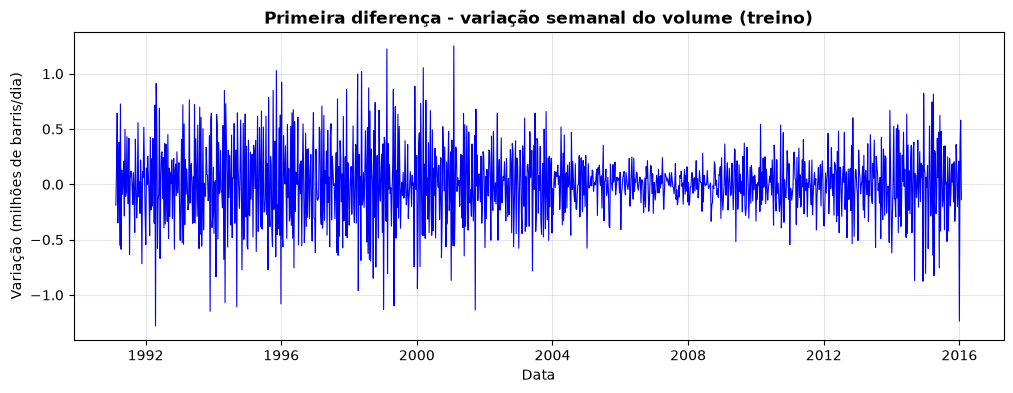

In [23]:
plt.figure(figsize=(12, 4))
plt.plot(dif1, color="blue", linewidth=0.8)
plt.title("Primeira diferença - variação semanal do volume (treino)", fontweight="bold")
plt.xlabel("Data")
plt.ylabel("Variação (milhões de barris/dia)")
plt.grid(alpha=0.3)
plt.show()

In [32]:
n_janelas = 5 # número de janelas
n_inicial = len(train_df) - h * n_janelas
window_inicial = train_df.iloc[:n_inicial]
print(f"Treino: {len(train_df)} semanas | Teste: {len(test_df)} semanas")
print(f"Treino inicial da CV: {n_inicial} semanas")

Treino: 1303 semanas | Teste: 52 semanas
Treino inicial da CV: 1043 semanas


In [33]:
error_opts = ['add', 'mul']
trend_opts = [None, 'add', 'mul']
seasonal_opts = [None, 'add', 'mul']

min_train_size = n_inicial
horizon = h
step_size = h

cv_starts = list(range(min_train_size, len(train_df) - horizon + 1, step_size))

best_cv_rmse = float('inf')
best_cv_model_name = None
best_cv_cfg = None

# Executar Grid Search avaliado via Cross Validation
for e in error_opts:
    for t in trend_opts:
        for s in seasonal_opts:
            rmses = []
            # Estrutura do laço de janelas em expansão
            for start in cv_starts:
                cv_train = train_df.iloc[:start]
                cv_val = train_df.iloc[start:start+horizon]

                try:
                    model_cv = ETSModel(cv_train['Volume_Milhoes_Barris_Dia'], error=e, trend=t, seasonal=s, seasonal_periods=m)
                    fit_cv = model_cv.fit(disp=False)
                    pred_cv = fit_cv.forecast(steps=horizon)

                    rmse = root_mean_squared_error(cv_val['Volume_Milhoes_Barris_Dia'], pred_cv)
                    rmses.append(rmse)
                except:
                    continue

            if len(rmses) == len(cv_starts) and np.isfinite(rmses).all():
                mean_rmse = np.mean(rmses)
                if mean_rmse < best_cv_rmse:
                    best_cv_rmse = mean_rmse
                    best_cv_model_name = f"ETS({e[0].upper()},{'N' if t is None else t[0].upper()},{'N' if s is None else s[0].upper()})"
                    best_cv_cfg = (e, t, s)

print(f"Melhor modelo por CV: {best_cv_model_name} com RMSE Médio Validado = {best_cv_rmse:.4f}")

c:\Users\giuli\Downloads\facul\ast-gasolina-eua\.venv\Lib\site-packages\statsmodels\tsa\exponential_smoothing\ets.py:1130: RuntimeWarning: overflow encountered in square
  logL = -self.nobs / 2 * (np.log(2 * np.pi * np.mean(res**2)) + 1)
c:\Users\giuli\Downloads\facul\ast-gasolina-eua\.venv\Lib\site-packages\statsmodels\tsa\exponential_smoothing\ets.py:1027: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\giuli\Downloads\facul\ast-gasolina-eua\.venv\Lib\site-packages\statsmodels\tsa\exponential_smoothing\ets.py:1027: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\giuli\Downloads\facul\ast-gasolina-eua\.venv\Lib\site-packages\statsmodels\tsa\exponential_smoothing\ets.py:1027: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\giuli\Downloads\facul\ast-gasolina-eua\.ve

Melhor modelo por CV: ETS(A,N,A) com RMSE Médio Validado = 0.3025


### SARIMA

In [24]:
pip install pmdarima

Note: you may need to restart the kernel to use updated packages.


In [25]:
from pmdarima import auto_arima

In [26]:
model = auto_arima(train_df.Volume_Milhoes_Barris_Dia, start_p = 1, start_q = 1, max_p = 4, max_q = 52, m = m, seasonal = True, start_P=1, start_Q=0, max_P=2,max_D = 1, trace= True, error_action="ignore", suppress_warnings=True, stepwise=True )

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,0,0)[52] intercept   : AIC=280.087, Time=6.74 sec
 ARIMA(0,1,0)(0,0,0)[52] intercept   : AIC=859.313, Time=0.07 sec
 ARIMA(1,1,0)(1,0,0)[52] intercept   : AIC=510.123, Time=3.88 sec
 ARIMA(0,1,1)(0,0,1)[52] intercept   : AIC=300.174, Time=4.52 sec
 ARIMA(0,1,0)(0,0,0)[52]             : AIC=857.349, Time=0.04 sec
 ARIMA(1,1,1)(0,0,0)[52] intercept   : AIC=357.929, Time=0.18 sec
 ARIMA(1,1,1)(2,0,0)[52] intercept   : AIC=238.719, Time=52.36 sec
 ARIMA(1,1,1)(2,0,1)[52] intercept   : AIC=200.104, Time=90.69 sec
 ARIMA(1,1,1)(1,0,1)[52] intercept   : AIC=inf, Time=11.39 sec
 ARIMA(1,1,1)(2,0,2)[52] intercept   : AIC=inf, Time=113.69 sec
 ARIMA(1,1,1)(1,0,2)[52] intercept   : AIC=inf, Time=97.47 sec
 ARIMA(0,1,1)(2,0,1)[52] intercept   : AIC=inf, Time=102.52 sec
 ARIMA(1,1,0)(2,0,1)[52] intercept   : AIC=inf, Time=52.89 sec
 ARIMA(2,1,1)(2,0,1)[52] intercept   : AIC=inf, Time=105.02 sec
 ARIMA(1,1,2)(2,0,1)[52] intercept   : AIC=inf

### Árvore de Decisão

In [36]:
profundidade_min = 1
profundidade_max = 10
resultados = []

for p in [1, 2, 4]:
    for i in range(profundidade_min, profundidade_max + 1):
        rmse_windows = []
        for step in range(n_janelas):
            fim = n_inicial + h * step
            window = train_df.iloc[:fim]
            val_set = train_df.iloc[fim:fim + h]

            # Preparando a série (lags)
            df_arvore = window[['Volume_Milhoes_Barris_Dia']].copy()
            for k in range(p):
                df_arvore[f'X_{k+1}'] = df_arvore.Volume_Milhoes_Barris_Dia.shift(k+1)
            df_arvore['month'] = df_arvore.index.month
            df_arvore.dropna(axis=0, inplace=True)

            # Variáveis preditoras (X: input) e variável alvo (y: output)
            X = df_arvore.drop('Volume_Milhoes_Barris_Dia', axis=1)
            y = df_arvore.Volume_Milhoes_Barris_Dia

            model = DecisionTreeRegressor(random_state=42, max_depth=i).fit(X, y)

            # Método recursivo para fazer predição para o horizonte h
            lag_vars = [f"X_{k+1}" for k in range(p)]
            lags = list(window.Volume_Milhoes_Barris_Dia.iloc[-p:][::-1])  # últimos valores observados (X_1 = mais recente)
            future_preds = []

            for data in val_set.index:
                # Cria o próximo vetor de entrada
                x_next = pd.DataFrame({var: [lags[k]] for k, var in enumerate(lag_vars)})
                x_next["month"] = [data.month]

                # Faz a previsão
                y_pred = model.predict(x_next)[0]
                future_preds.append(y_pred)

                # Atualiza os lags (shift: o mais recente entra na frente)
                lags = [y_pred] + lags[:-1]

            rmse_windows.append(root_mean_squared_error(val_set.Volume_Milhoes_Barris_Dia, future_preds))

        resultados.append({"p": p, "max_depth": i, "RMSE": np.mean(rmse_windows)})

Tabela_Arvore = pd.DataFrame(resultados).sort_values("RMSE")
Tabela_Arvore.head(10)

C:\Users\giuli\AppData\Local\Temp\ipykernel_20328\1961459176.py:18: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_arvore.dropna(axis=0, inplace=True)
C:\Users\giuli\AppData\Local\Temp\ipykernel_20328\1961459176.py:18: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_arvore.dropna(axis=0, inplace=True)
C:\Users\giuli\AppData\Local\Temp\ipykernel_20328\1961459176.py:18: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_arvore.dropna(axis=0, inplace=True)
C:\Users\giuli\AppD

,p,max_depth,RMSE
27,4,8,0.450656
26,4,7,0.455791
19,2,10,0.456726
1,1,2,0.458083
24,4,5,0.478763
0,1,1,0.490274
23,4,4,0.506594
29,4,10,0.508588
15,2,6,0.508883
21,4,2,0.523046


In [37]:
melhor_arvore = Tabela_Arvore.iloc[0]
print(f"Modelo escolhido pela CV: p = {int(melhor_arvore['p'])}, max_depth = {int(melhor_arvore['max_depth'])}")
print(f"RMSE médio na CV: {melhor_arvore['RMSE']:.4f}")

Modelo escolhido pela CV: p = 4, max_depth = 8
RMSE médio na CV: 0.4507


### Prophet

### LSTM

## <font color = Blue> **Parte 5 - Avaliação do modelo no conjunto de teste**

- **Treine o modelo escolhido em todo o conjunto de treino**;
- **Avalie o modelo (escolhido na Parte 4) no conjunto de teste**. Para isso:
  - Faça a predição dos **`h` semanas**, sem utilizar valores reais do teste para atualizar as previsões, e compare com os dados observados;
  - Inclua **intervalo de previsão de 95% quando o modelo oferecer esse recurso**; caso contrário, justifique sua ausência;
  - Calcule o **RMSE no conjunto de teste, na escala original**;
- Não utilize o resultado do teste para trocar ou reajustar a configuração do modelo escolhido.


## <font color = Blue> **Parte 6 - Predição (forecast)**

- **Após concluir a avaliação, treine o modelo escolhido na série completa (treino + teste)**, mantendo a configuração selecionada;
- **Faça a predição para os próximos `h` semanas**, incluindo plot e intervalo de previsão de 95% quando disponível; caso contrário, justifique sua ausência.
